# PORTFOLIO P&L WITH SIMULATIONS

In [1]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

In [2]:
V0=100_000

In [3]:
prices=yf.download(["AAPL", "MSFT","NVDA"], period="1y").Close.dropna()

[*********************100%***********************]  3 of 3 completed


In [4]:
returns = np.log(prices/prices.shift(1)).dropna()

In [5]:
R=returns.corr()
R

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.000000,0.155491,0.059993
MSFT,0.155491,1.000000,0.233442
NVDA,0.059993,0.233442,1.000000


In [6]:
corr_matrix=returns.corr()

In [7]:
s0=prices.iloc[-1]
mu=np.mean(returns, axis=0)*252
std=np.std(returns, axis=0)*np.sqrt(252)
T=1

In [8]:
def st_cholesky(s0,mu,std,T,n_paths, corr_matrix):
    i=0
    n_assets=len(list(mu))
    epsilon=np.random.normal(0,1,[n_assets,n_paths])
    L=np.linalg.cholesky(corr_matrix)
    z=L@epsilon
    st = {}
    for ticker in s0.keys() :
        print(ticker)
        st[ticker] = s0.loc[ticker]*np.exp((mu.loc[ticker] - std.loc[ticker]**2/2)*T + std.loc[ticker]*np.sqrt(T)*z[i, :])

        i += 1
    return st
portfolio=st_cholesky(s0,mu,std,1,10_000,corr_matrix)

AAPL
MSFT
NVDA


In [9]:
w1= [1,0,0]
w2= [0.33,0.33,0.34]
w3= [0.2,0.2,0.6]
w= [w1,w2,w3]


In [10]:
n_portfolio = np.array(w)*V0/np.array(list(s0))

Vt=n_portfolio@np.array(list(portfolio.values()))
PL=Vt-V0
PL


array([[ 62081.47369743,  83456.33507971,  30788.1505073 , ...,
        -12673.05493282,   3610.40063946,  12340.86362319],
       [ 33161.55189283,   7997.34712193, -21071.14335998, ...,
        -13925.31183627, -29829.68120578,  -6389.53919597],
       [ 40536.83103533,   7171.82930421, -32995.86802804, ...,
        -29646.26374739, -31396.11620027, -11576.44840976]],
      shape=(3, 10000))

In [11]:
VaR=[]
cVaR=[]
mean=[]
median=[]
q1=[]
q3=[]
for i in range(3):
    VaR.append(np.percentile(PL[i],5))
    mean.append(np.mean(PL[i]))
    median.append(np.percentile(PL[i],50))
    q1.append(np.percentile(PL[i],25))
    q3.append(np.percentile(PL[i],75))
    cVaR.append(np.mean(PL[i][PL[i] <= VaR[i]]))

cVaR 24606.874083318166
VaR 16169.387184121195


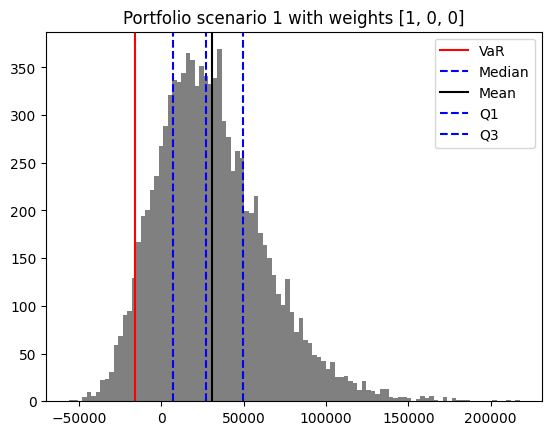

cVaR 30872.40557298439
VaR 24797.641020489198


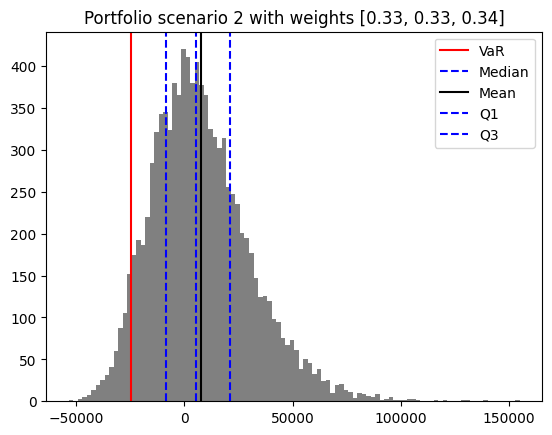

cVaR 39564.70701153619
VaR 33445.35877224314


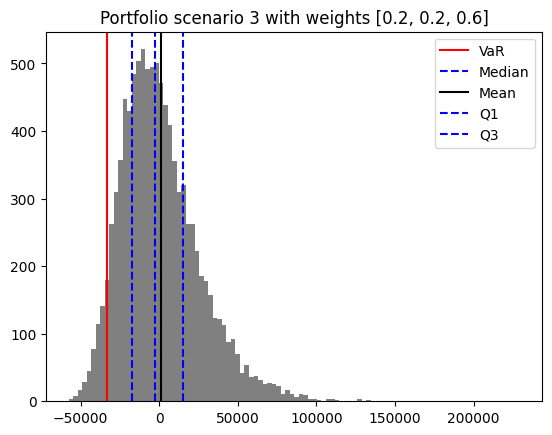

In [12]:
for i in range(3):
    print("cVaR", -cVaR[i])
    print("VaR", -VaR[i] )
    plt.hist(PL[i], bins=100, color="grey")
    plt.axvline(VaR[i], color="red", label="VaR")
    plt.axvline(median[i], color="blue", label="Median", linestyle="dashed")
    plt.axvline(mean[i], color="black", label="Mean")
    plt.axvline(q1[i], color="blue", label="Q1", linestyle="dashed")
    plt.axvline(q3[i], color="blue", label="Q3", linestyle="dashed")
    plt.title(f"Portfolio scenario {i+1} with weights {w[i]}")
    plt.legend()
    plt.show()
    

## Conclusion

Although VaR is a useful risk metric, it only identifies a loss threshold and does not measure the magnitude of losses beyond that point. Therefore, CVaR is particularly important in this exercise because it estimates the average loss within the worst 5% of simulated outcomes. This is especially relevant because the P&L distribution appears asymmetric and potentially non-normal, as suggested by the difference between the mean and the median and by the shape of the histogram. Consequently, relying solely on VaR may underestimate tail risk, whereas CVaR provides a clearer view of the severity of potential extreme losses.